# C1 MF 학습

A4에서 나눈 `train`으로 Matrix Factorization(MF)을 학습하고 학습 곡선(epoch별 오차)을 그립니다.

1. 평점만으로 학습한 MF의 학습 곡선과 검증 RMSE
2. 그 모델로 추천(top-10)했을 때의 점수와 문제점
3. 평점 없는 칸을 0점으로 함께 학습한 MF(negative sampling)의 학습 곡선

설정 비교는 `C2_mf_tuning.ipynb`, 신규 독자용 fold-in은 `C3_fold_in.ipynb`에 있습니다.
학습은 `train`만 쓰고, 점수는 `val`로만 잽니다. `test`와 `cold_final`은 쓰지 않습니다.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bookrec.data import load_split
from bookrec.evaluation import evaluate_rmse, evaluate_warm
from bookrec.models.collaborative_filtering import MatrixFactorization
from bookrec.models.collaborative_filtering.tuning import RESULT_DIR, TUNING_USERS, result_rows
from bookrec.models.popularity import PopularityRecommender
from bookrec.plot_style import MODEL_COLORS, save, setup

setup()
split = load_split()
print(f"train {len(split.train):,}건 / val {len(split.val):,}건 / 독자 {split.train['user_id'].nunique():,}명")

train 3,769,078건 / val 811,075건 / 독자 48,424명


## 1. 평점만으로 학습한 MF

예측 별점 = 전체 평균 + 독자 bias + 책 bias + (독자 벡터 · 책 벡터)

- 독자 bias: 그 독자가 평소에 후하게(또는 짜게) 주는 정도
- 책 bias: 그 책이 평소에 후하게(또는 짜게) 받는 정도
- 독자 벡터 · 책 벡터: 그 독자의 취향과 그 책의 성격이 맞는 정도

평점 하나의 loss는 `(실제 별점 - 예측 별점)^2 + reg * (파라미터 크기^2)`이고, mini-batch gradient descent로 줄입니다.
구현은 `src/bookrec/models/collaborative_filtering/mf.py`에 있습니다(NumPy로 직접 구현).

기본 설정(잠재 차원 32, 학습률 0.01, 정규화 0.05, batch 2,048)으로 25 epoch를 끝까지 돌려,
검증 RMSE가 어디서부터 다시 커지는지 봅니다. `patience=25`로 두어 중간에 멈추지 않게 했습니다.

In [2]:
started = time.time()
rating_model = MatrixFactorization(n_factors=32, lr=0.01, reg=0.05, n_epochs=25, patience=25)
rating_model.fit(split.train, val=split.val)
print(f"학습 시간 {time.time() - started:.0f}초, 검증 RMSE가 가장 낮은 epoch = {rating_model.best_epoch}")
rating_history = rating_model.history
rating_history.to_csv(RESULT_DIR / "C1_rating_history.csv", index=False)
rating_history.round(4)

학습 시간 150초, 검증 RMSE가 가장 낮은 epoch = 21


,epoch,train_rmse,val_rmse
0,1,0.9159,0.8805
1,2,0.8632,0.8671
2,3,0.8504,0.8644
3,4,0.8456,0.8640
4,5,0.8425,0.8637
5,6,0.8396,0.8629
6,7,0.8359,0.8623
7,8,0.8312,0.8609
8,9,0.8256,0.8599
9,10,0.8193,0.8583


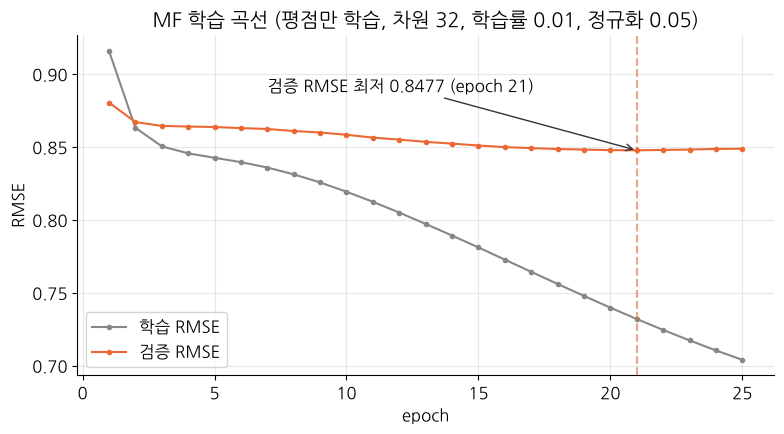

In [3]:
fig, ax = plt.subplots()
ax.plot(rating_history["epoch"], rating_history["train_rmse"], color=MODEL_COLORS["baseline"], marker="o", markersize=3, label="학습 RMSE")
ax.plot(rating_history["epoch"], rating_history["val_rmse"], color=MODEL_COLORS["mf"], marker="o", markersize=3, label="검증 RMSE")
# NOTE: axvline(x)는 x 위치에 세로선을 긋는다. linestyle="--"는 점선이다.
ax.axvline(rating_model.best_epoch, color=MODEL_COLORS["mf"], linestyle="--", alpha=0.6)
best_rmse = rating_history["val_rmse"].min()
ax.annotate(f"검증 RMSE 최저 {best_rmse:.4f} (epoch {rating_model.best_epoch})",
            xy=(rating_model.best_epoch, best_rmse), xytext=(rating_model.best_epoch - 14, best_rmse + 0.04),
            arrowprops={"arrowstyle": "->", "color": "#333333"})
ax.set_xlabel("epoch")
ax.set_ylabel("RMSE")
ax.set_title("MF 학습 곡선 (평점만 학습, 차원 32, 학습률 0.01, 정규화 0.05)")
ax.legend()
save(fig, "C1_mf_loss_curve")
plt.show()

비교 기준으로, 모든 평점을 `train` 전체 평균으로 예측했을 때의 검증 RMSE를 함께 잽니다.

In [4]:
mean_rmse = float(np.sqrt(np.mean((split.val["rating"] - split.train["rating"].mean()) ** 2)))
mf_rmse = evaluate_rmse(rating_model, split, on="val")
print(f"전체 평균으로 예측: 검증 RMSE {mean_rmse:.4f}")
print(f"MF (평점만 학습): 검증 RMSE {mf_rmse:.4f}  (전체 평균 대비 {100 * (1 - mf_rmse / mean_rmse):.1f}% 감소)")

전체 평균으로 예측: 검증 RMSE 0.9865
MF (평점만 학습): 검증 RMSE 0.8477  (전체 평균 대비 14.1% 감소)


## 2. 이 모델로 추천하면

같은 모델의 예측 별점이 높은 순으로 10권을 추천하고, 인기순 기준선과 비교합니다(val 독자 5,000명, 시드 고정).

In [5]:
popularity = PopularityRecommender().fit(split.train)
warm_popularity = evaluate_warm(popularity, split, on="val", n_users=TUNING_USERS)
warm_rating = evaluate_warm(rating_model, split, on="val", n_users=TUNING_USERS)
pd.DataFrame([warm_popularity, warm_rating], index=["인기순", "MF (평점만 학습)"]).round(4)

,precision@10,recall@10,ndcg@10,users
인기순,0.0342,0.0308,0.0382,4974
MF (평점만 학습),0.0029,0.0029,0.0031,4974


별점 예측은 전체 평균보다 좋아졌지만, 추천 적중률은 인기순보다 낮습니다. 추천된 책이 어떤 책인지 봅니다.

In [6]:
sample_users = split.train["user_id"].drop_duplicates().sample(1000, random_state=42)
sample_history = split.train[split.train["user_id"].isin(sample_users)]
counts = split.train["book_id"].value_counts()
for name, model in [("인기순", popularity), ("MF (평점만 학습)", rating_model)]:
    recommended = pd.Series(model.recommend(sample_history)).explode().astype(int)
    print(f"{name}: 추천된 책의 train 평점 수 중앙값 = {counts.reindex(recommended, fill_value=0).median():,.0f}개 "
          f"(전체 책의 중앙값 {counts.median():,.0f}개), 서로 다른 책 {recommended.nunique():,}권")

인기순: 추천된 책의 train 평점 수 중앙값 = 11,421개 (전체 책의 중앙값 145개), 서로 다른 책 43권


MF (평점만 학습): 추천된 책의 train 평점 수 중앙값 = 122개 (전체 책의 중앙값 145개), 서로 다른 책 767권


평점만 학습한 MF는 "읽은 책에 몇 점을 줄지"만 배우고 "어떤 책을 읽을지"는 배우지 않습니다.
그래서 평점 수가 적고 평균 별점이 높은 책에 높은 예측 별점을 주게 되고, 그 책들은 독자가 실제로 읽을 가능성이 낮아 적중하지 않습니다.

## 3. 평점 없는 칸을 0점으로 함께 학습 (negative sampling)

평점 1개마다 무작위 책 `neg_ratio`권을 뽑아 "정답 0점"으로 함께 학습합니다.
독자가 평가하지 않은 책은 0점에 가깝게, 평가한 책은 별점에 가깝게 예측하도록 배우므로
점수가 높은 책 = "읽을 것 같고, 읽으면 높게 줄 것 같은 책"이 됩니다. loss와 갱신식은 그대로이고 학습에 넣는 정답만 늘어납니다.

기본 설정(neg_ratio 2, 학습률 0.02)으로 학습하면서 epoch마다 val NDCG@10(독자 5,000명)을 잽니다.
NDCG@10이 3번 연속으로 나아지지 않으면 멈추고, 가장 좋았던 epoch의 파라미터로 되돌립니다.

In [7]:
monitor = lambda model: evaluate_warm(model, split, on="val", n_users=TUNING_USERS)["ndcg@10"]
started = time.time()
ranking_model = MatrixFactorization(n_factors=32, lr=0.02, reg=0.05, neg_ratio=2, n_epochs=20, patience=3)
ranking_model.fit(split.train, val=split.val, monitor=monitor)
print(f"학습 시간 {time.time() - started:.0f}초, val NDCG@10이 가장 높은 epoch = {ranking_model.best_epoch}")
ranking_history = ranking_model.history.rename(columns={"monitor": "val_ndcg@10"})
ranking_history.to_csv(RESULT_DIR / "C1_ranking_history.csv", index=False)
ranking_history.round(4)

학습 시간 133초, val NDCG@10이 가장 높은 epoch = 4


,epoch,train_rmse,val_rmse,val_ndcg@10
0,1,1.6027,2.1850,0.0549
1,2,1.3566,1.9841,0.0579
2,3,1.2477,1.9507,0.0586
3,4,1.2054,1.9427,0.0601
4,5,1.1860,1.9383,0.0588
5,6,1.1762,1.9393,0.0582
6,7,1.1712,1.9367,0.0584


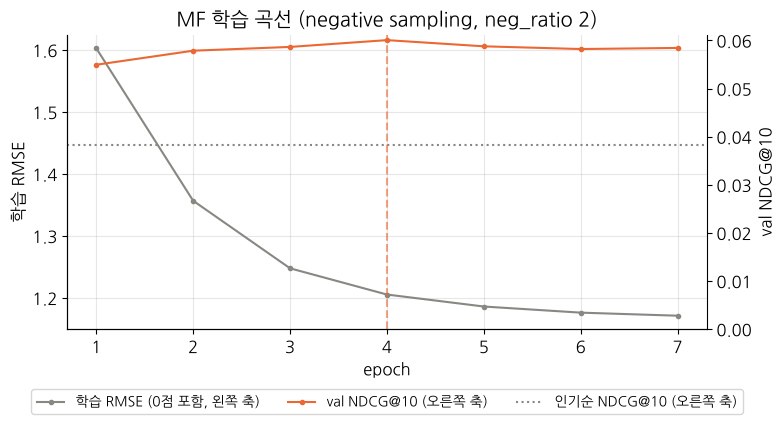

In [8]:
fig, ax = plt.subplots()
ax.plot(ranking_history["epoch"], ranking_history["train_rmse"], color=MODEL_COLORS["baseline"], marker="o", markersize=3, label="학습 RMSE (0점 포함, 왼쪽 축)")
ax.set_xlabel("epoch")
ax.set_ylabel("학습 RMSE")
# NOTE: twinx()는 x축을 같이 쓰고 y축만 오른쪽에 따로 두는 축을 만든다. 단위가 다른 두 값을 한 그래프에 그릴 때 쓴다.
right = ax.twinx()
right.plot(ranking_history["epoch"], ranking_history["val_ndcg@10"], color=MODEL_COLORS["mf"], marker="o", markersize=3, label="val NDCG@10 (오른쪽 축)")
right.axhline(warm_popularity["ndcg@10"], color=MODEL_COLORS["baseline"], linestyle=":", label="인기순 NDCG@10 (오른쪽 축)")
right.axvline(ranking_model.best_epoch, color=MODEL_COLORS["mf"], linestyle="--", alpha=0.6)
right.set_ylabel("val NDCG@10")
right.set_ylim(0, None)
right.grid(False)
right.spines["right"].set_visible(True)
# NOTE: 두 축의 범례를 하나로 합친다. get_legend_handles_labels()는 (선 목록, 이름 목록)을 돌려준다.
handles = ax.get_legend_handles_labels()[0] + right.get_legend_handles_labels()[0]
labels = ax.get_legend_handles_labels()[1] + right.get_legend_handles_labels()[1]
# NOTE: bbox_to_anchor=(0.5, -0.18)은 범례를 그래프 아래 가운데에 둔다. ncol=3은 한 줄에 3개를 놓는다.
ax.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=10)
ax.set_title("MF 학습 곡선 (negative sampling, neg_ratio 2)")
save(fig, "C1_mf_ranking_curve")
plt.show()

## 4. 정리

같은 val 독자 5,000명으로 세 모델을 비교합니다.

In [9]:
warm_ranking = evaluate_warm(ranking_model, split, on="val", n_users=TUNING_USERS)
scores = pd.concat([
    result_rows("popularity", "warm_val", warm_popularity),
    result_rows("mf_rating", "warm_val", warm_rating),
    result_rows("mf_ranking", "warm_val", warm_ranking),
], ignore_index=True)
scores["val_rmse"] = [np.nan, mf_rmse, evaluate_rmse(ranking_model, split, on="val")]
scores.to_csv(RESULT_DIR / "C1_validation_scores.csv", index=False)
scores.round(4)

,model,goal,history_size,precision@10,recall@10,ndcg@10,users,val_rmse
0,popularity,warm_val,all,0.0342,0.0308,0.0382,4974,NaN
1,mf_rating,warm_val,all,0.0029,0.0029,0.0031,4974,0.8477
2,mf_ranking,warm_val,all,0.0535,0.0500,0.0601,4974,1.9427


- 평점만 학습한 MF는 RMSE가 좋지만 추천 적중률은 인기순보다 낮습니다.
- 0점을 함께 학습한 MF는 추천 적중률이 인기순보다 높습니다. 대신 예측값이 별점보다 낮아져 RMSE는 나빠집니다.
- 그래서 별점 예측(RMSE)에는 평점만 학습한 MF를, 추천(top-10)과 hybrid에는 0점을 함께 학습한 MF를 씁니다.
  두 모델의 설정은 C2에서 각각 고릅니다.